# RouteVision：U-Net 逐像素預測繞線使用率圖

前面的方法都是「8×8 區塊，熱點或不是」。這份 notebook 加入**逐像素預測**：U-Net 直接預測 routing 後整張 256×256 的繞線使用率圖（監督式回歸，仍是鑑別式模型），再取每個區塊的平均當熱點分數，和其他方法放在同一張表比較。

- **模型**：U-Net，編碼器為 ImageNet 預訓練的 ResNet-18（輸入改成 4 通道），約 14 M 參數。
- **兩個版本（消融）**：`U-Net`（只用影像）、`U-Net (multimodal)`（設計參數以 FiLM 調整瓶頸層特徵）。
- **評估**：和其他方法一樣三個設計輪流當測試。像素層級：Pearson、SSIM、NRMSE，對照 eGR（原始值，同單位）與用訓練設計線性校正的 eGR、RUDY。區塊層級：ROC-AUC、F1 等，閾值在驗證集決定。
- **事先定好的規則**：網頁使用三設計平均像素 Pearson 較高的版本。

### 執行步驟（Colab，T4 GPU，約 20–30 分鐘）
1. 把 `RouteVision_v3.zip` 上傳到 Google Drive 的 `MyDrive/`（和之前放同一個地方）。
2. 「執行階段 → 變更執行階段類型」選 **T4 GPU**。
3. 「執行階段 → 全部執行」。模型存在 Drive 的 `MyDrive/RouteVision/checkpoints_unet/`，斷線後重跑會從中斷處繼續。
4. 最後一格會下載 `RouteVision_results_unet.zip`（約 120 MB），把它交給本機專案（Claude 會解壓並匯出給網頁）。

In [1]:
# 環境設定：掛載 Drive；解壓新版程式（覆蓋程式碼，但不覆蓋已存在的資料與模型）
import os, sys, json
from google.colab import drive
drive.mount('/content/drive')
PROJECT = '/content/drive/MyDrive/RouteVision'
ZIP = '/content/drive/MyDrive/RouteVision_v3.zip'
!unzip -q -n {ZIP} -d /content/drive/MyDrive/
!unzip -q -o {ZIP} 'RouteVision/routevision/*' 'RouteVision/notebooks/*' -d /content/drive/MyDrive/
os.chdir(PROJECT); sys.path.insert(0, PROJECT)
%matplotlib inline
import torch
print('device:', torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU（請改用 T4 GPU）')

Mounted at /content/drive
device: Tesla T4


## 1. 三個設計輪流測試 × 兩個 U-Net 版本
每一輪：在其餘兩個設計上訓練（85% 訓練、15% 驗證，和其他方法完全相同的切分），以驗證集 MSE 最低的 epoch 為準，只在測試設計上評估。

In [2]:
from routevision import pixel as P
import pandas as pd
pd.set_option('display.width', 220); pd.set_option('display.max_columns', 30)
DESIGNS = ['Vortex-small', 'nvdla-small', 'openc910-1']
patch, pixel, chosen = P.cross_design('data/processed', DESIGNS)
print(json.dumps(chosen, indent=1, ensure_ascii=False))


=== test design: Vortex-small ===
train:  164 layouts,  10496 windows, hotspot rate 0.388, designs ['nvdla-small', 'openc910-1']
val  :   28 layouts,   1792 windows, hotspot rate 0.390, designs ['nvdla-small', 'openc910-1']
test :   96 layouts,   6144 windows, hotspot rate 0.232, designs ['Vortex-small']
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 210MB/s]


  [U-Net] epoch  1/60 | train MSE 0.07268 | val MSE 0.08713 | val Pearson 0.4548
  [U-Net] epoch  2/60 | train MSE 0.04260 | val MSE 0.03587 | val Pearson 0.7551
  [U-Net] epoch  3/60 | train MSE 0.02889 | val MSE 0.02418 | val Pearson 0.8190
  [U-Net] epoch  4/60 | train MSE 0.02462 | val MSE 0.02166 | val Pearson 0.8417
  [U-Net] epoch  5/60 | train MSE 0.02146 | val MSE 0.01988 | val Pearson 0.8560
  [U-Net] epoch  6/60 | train MSE 0.01974 | val MSE 0.02022 | val Pearson 0.8557
  [U-Net] epoch  7/60 | train MSE 0.01954 | val MSE 0.01848 | val Pearson 0.8698
  [U-Net] epoch  8/60 | train MSE 0.01821 | val MSE 0.01825 | val Pearson 0.8739
  [U-Net] epoch  9/60 | train MSE 0.01723 | val MSE 0.01737 | val Pearson 0.8762
  [U-Net] epoch 10/60 | train MSE 0.01631 | val MSE 0.01601 | val Pearson 0.8849
  [U-Net] epoch 11/60 | train MSE 0.01568 | val MSE 0.01566 | val Pearson 0.8879
  [U-Net] epoch 12/60 | train MSE 0.01548 | val MSE 0.01598 | val Pearson 0.8879
  [U-Net] epoch 13/60 | trai

## 2. 結果
- 像素層級：各設計當測試時的 Pearson，以及三設計的平均 ± 標準差。
- 區塊層級：和其他方法同一套指標；`layouts_beating_eGR` 為逐張版圖 F1 贏過 eGR 的數量（3 個設計共 288 張）。

In [3]:
px, pa = P.summarize(patch, pixel)
display(pixel.pivot_table(index='method', columns='test_design', values='Pearson', sort=False).round(4))
display(px)
display(pa)

test_design,Vortex-small,nvdla-small,openc910-1
method,,,
U-Net,0.7284,0.8112,0.8861
U-Net (multimodal),0.7137,0.8175,0.8954
eGR (EDA estimate),0.5885,0.5408,0.8247
eGR (linear calibrated),0.5934,0.5413,0.8251
RUDY (linear calibrated),0.4564,0.5086,0.6928


Pearson            SSIM           NRMSE        
                            mean     std    mean     std    mean     std
method                                                                  
U-Net                     0.8086  0.0789  0.4527  0.1068  0.1650  0.0231
U-Net (multimodal)        0.8089  0.0911  0.4526  0.1582  0.1616  0.0292
eGR (EDA estimate)        0.6513  0.1520  0.2433  0.0709  0.3354  0.0198
eGR (linear calibrated)   0.6533  0.1510  0.2846  0.0698  0.2035  0.0318
RUDY (linear calibrated)  0.5526  0.1242  0.1481  0.0187  0.2319  0.0180

,ROC-AUC,PR-AUC,F1(hotspot),Macro-F1,mean_layout_F1,layouts_beating_eGR
method,,,,,,
U-Net,0.9702,0.8774,0.7768,0.8498,0.7459,155 / 288
U-Net (multimodal),0.9837,0.9369,0.8482,0.8960,0.8174,191 / 288


Vortex-small


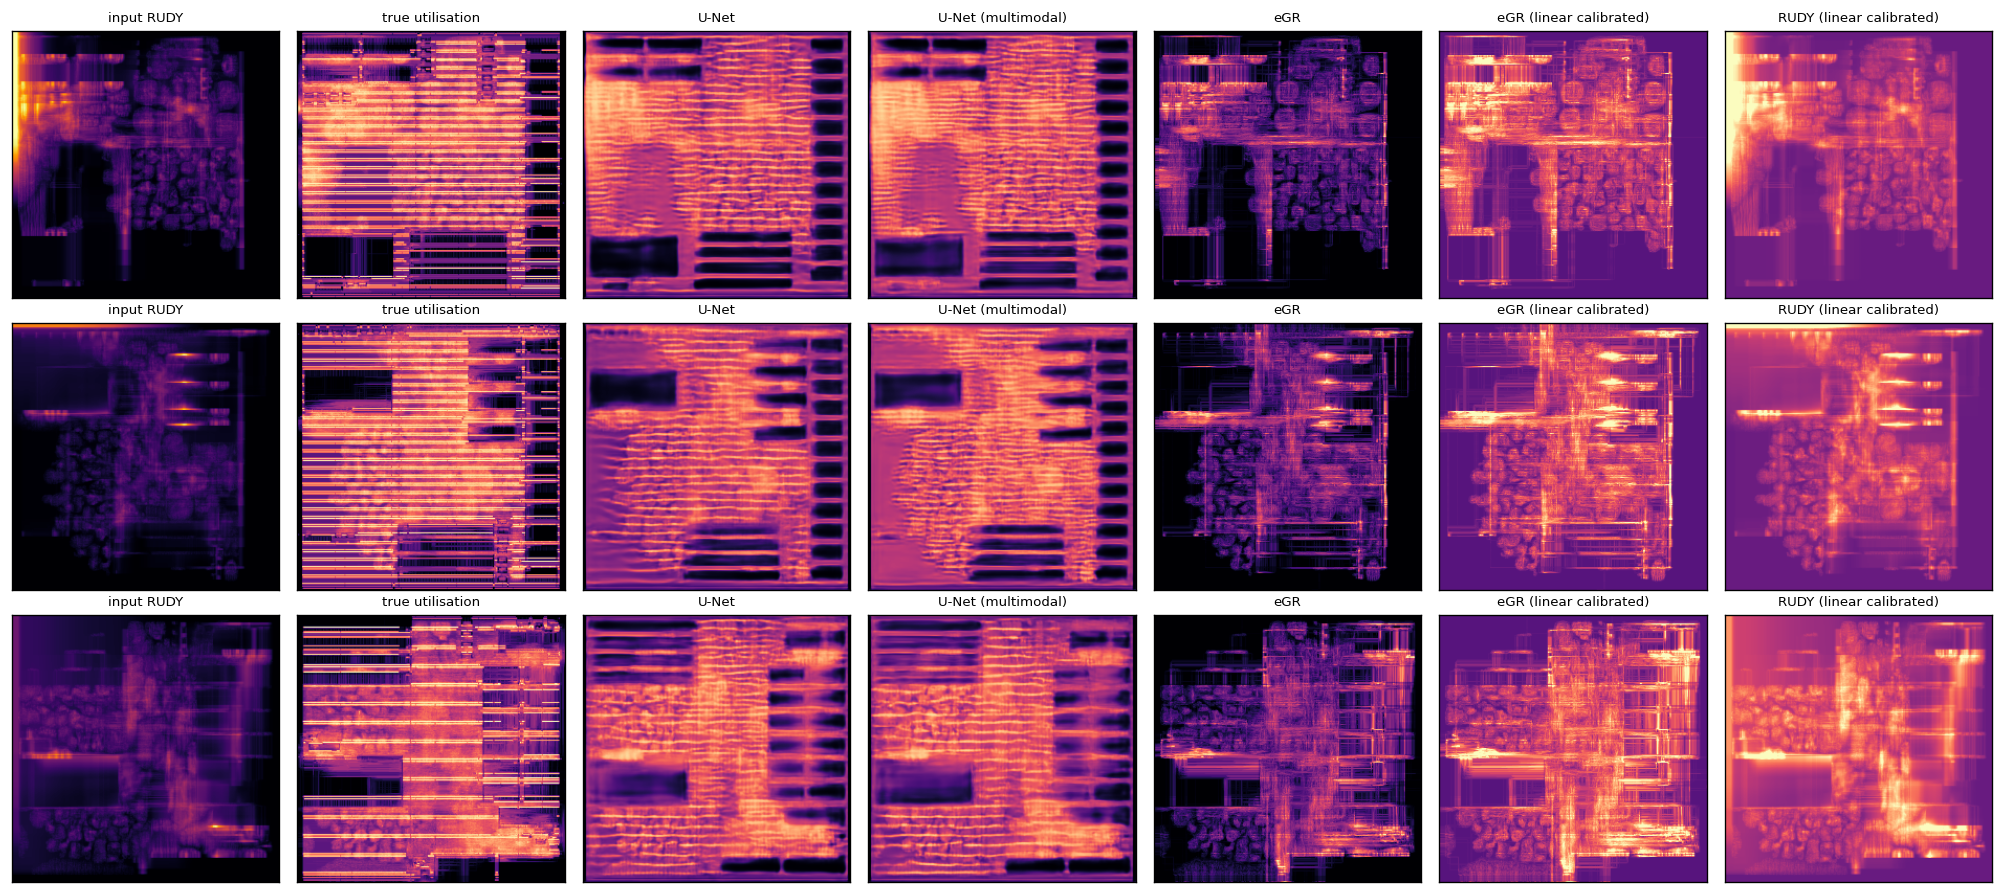

nvdla-small


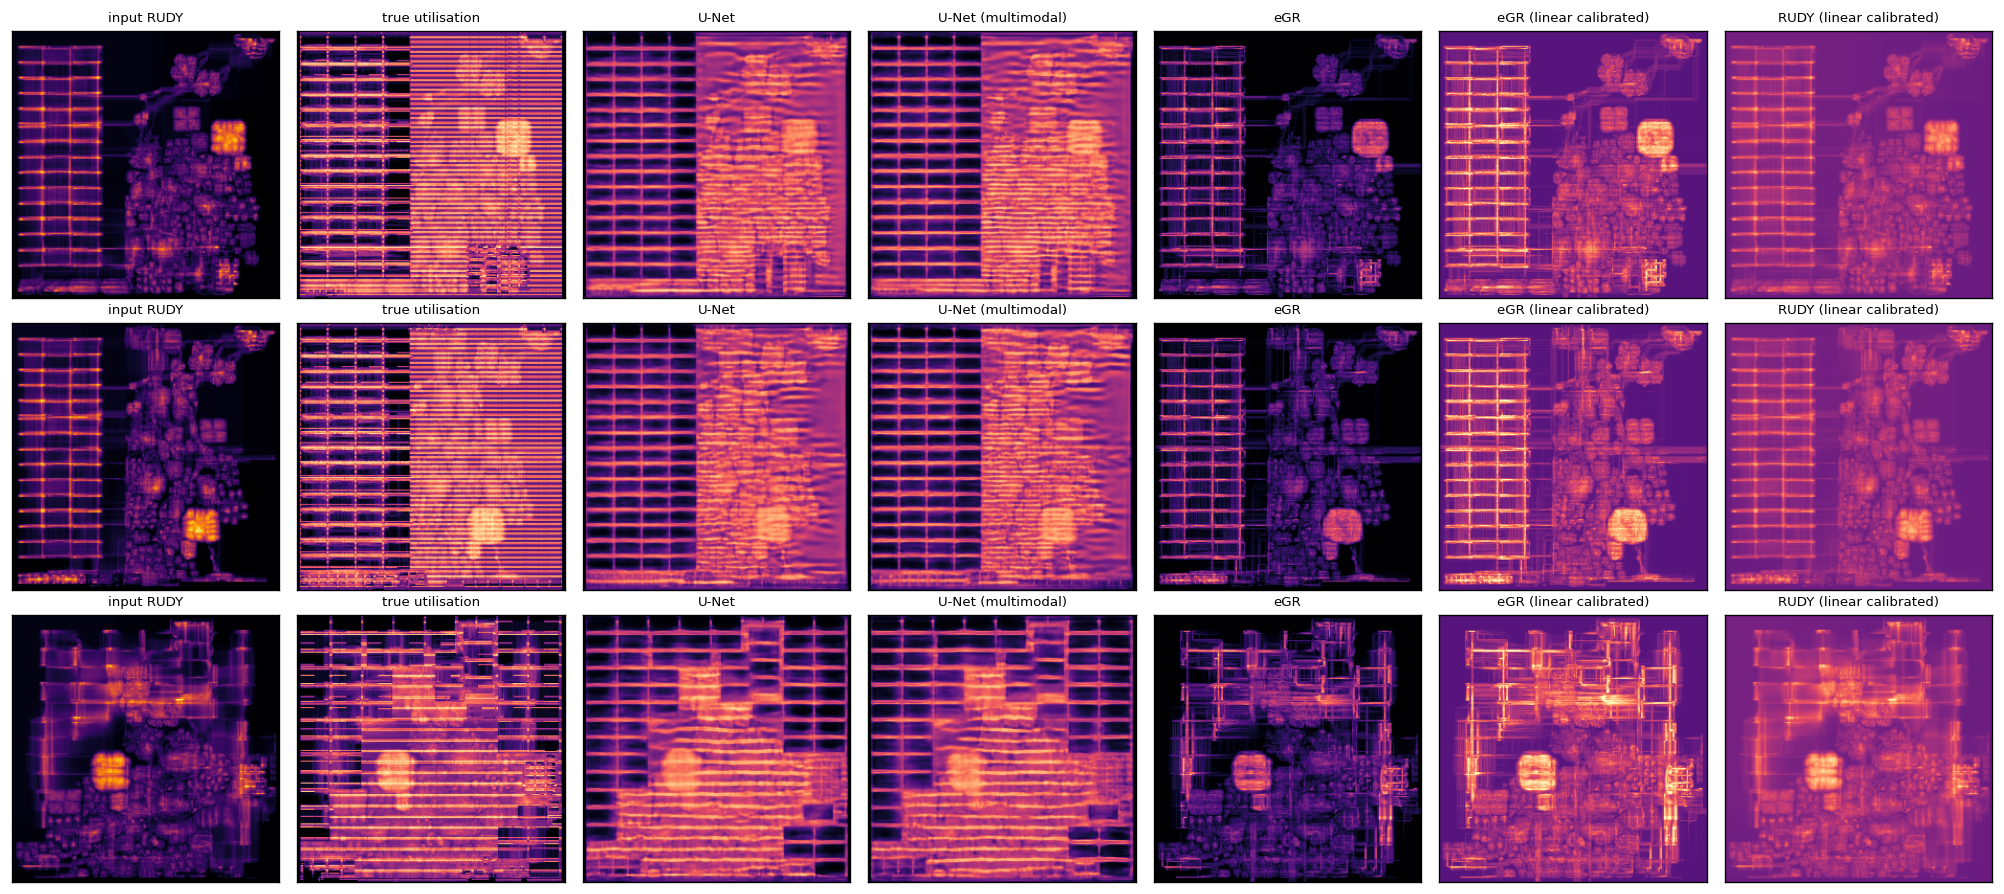

openc910-1


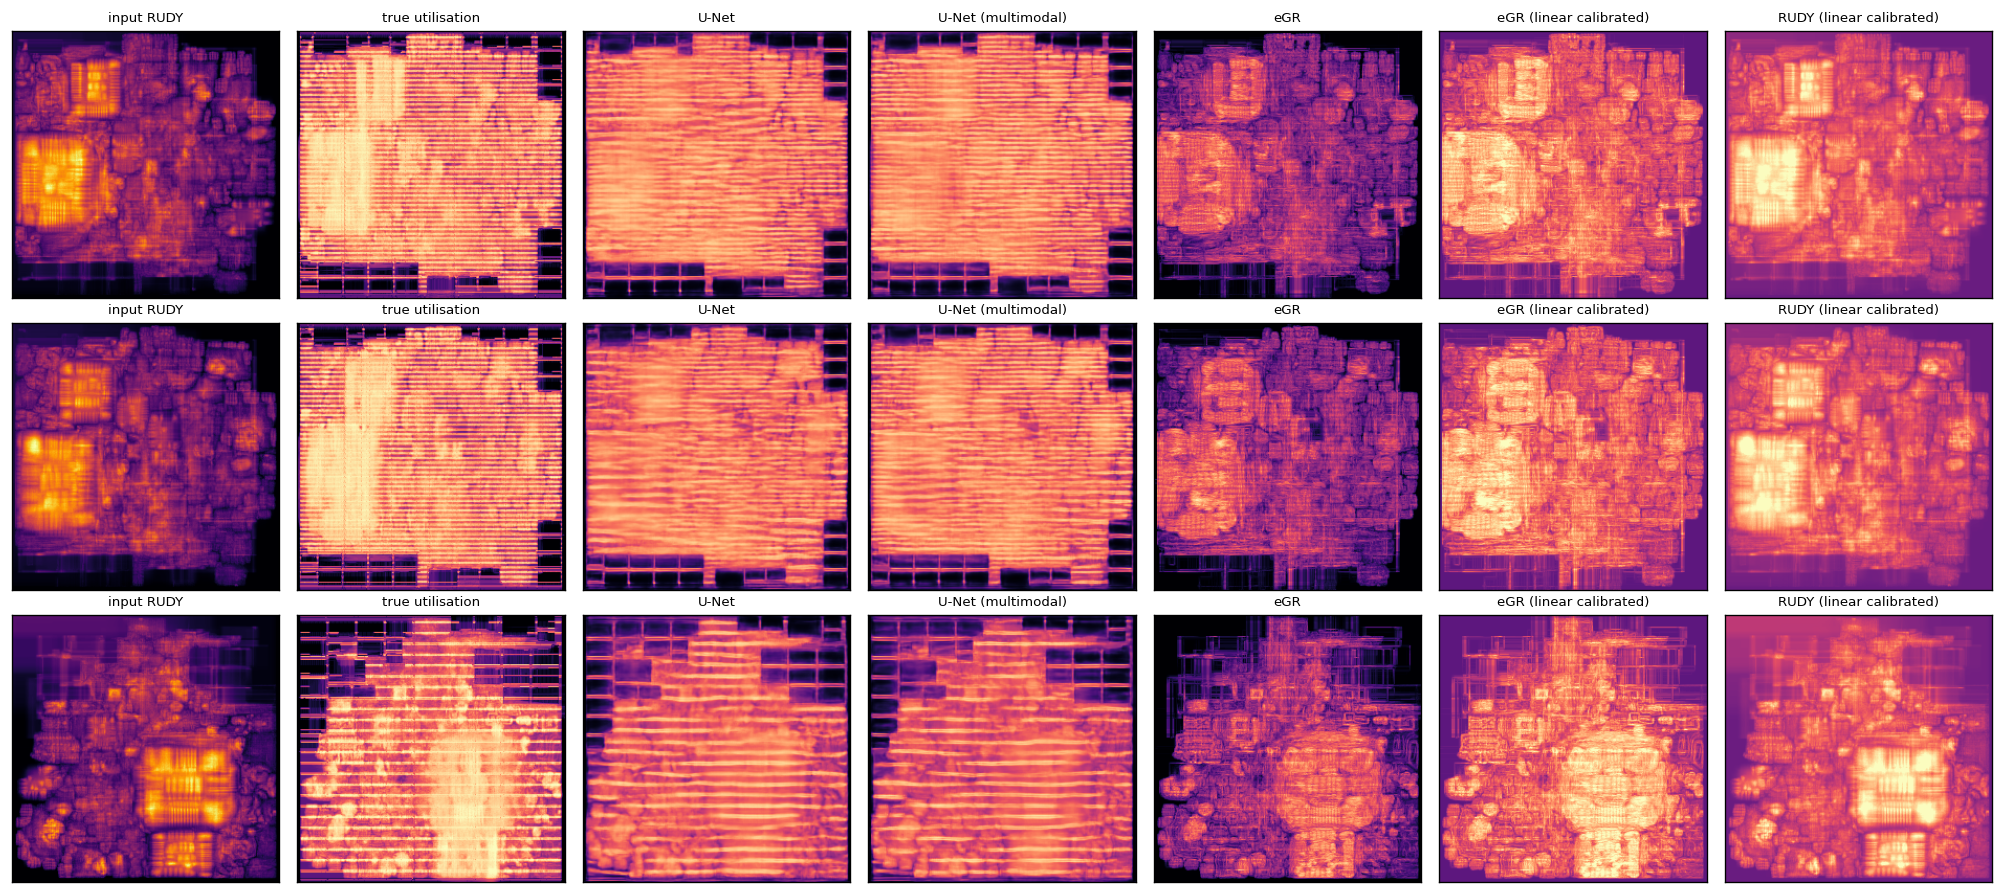

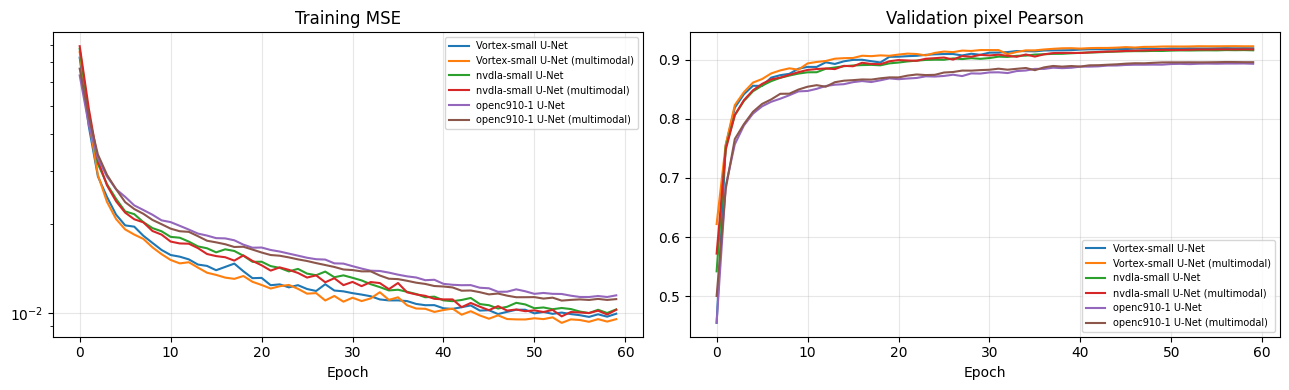

In [4]:
import matplotlib.pyplot as plt
from IPython.display import Image, display as show
for d in DESIGNS:
    print(d); show(Image(f'outputs/unet/{d}/maps.png'))

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for d in DESIGNS:
    for name, stem in (('U-Net', 'UNet'), ('U-Net (multimodal)', 'UNet_multimodal')):
        h = json.load(open(f'checkpoints_unet/{d}/{stem}.json'))
        ax[0].plot(h['train_mse'], label=f'{d} {name}'); ax[1].plot(h['val_pearson'], label=f'{d} {name}')
ax[0].set(title='Training MSE', xlabel='Epoch', yscale='log'); ax[1].set(title='Validation pixel Pearson', xlabel='Epoch')
for a in ax: a.legend(fontsize=7); a.grid(alpha=0.3)
fig.tight_layout(); fig.savefig('outputs/unet/training_curves.png', dpi=150); plt.show()

## 3. 打包下載（結果與網頁要用的 Vortex-small 那一輪模型）

In [5]:
!cd {PROJECT} && rm -f /content/RouteVision_results_unet.zip && zip -q -r /content/RouteVision_results_unet.zip outputs/unet checkpoints_unet/Vortex-small
from google.colab import files
files.download('/content/RouteVision_results_unet.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>